Live Deployment Link: <https://house-price-prediction-shaiza-butt.streamlit.app/>

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses (XGBoost is pre-installed on Colab).

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `House_price_prediction_kfold.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select **`kc_house_data.csv`** from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload the CSV.

---

## Introduction

##### **Definition** A regression ML task that predicts the sale price (USD) of a house in King County, Washington (the Seattle area) from its size, quality, age and location.
##### **Application** Real-estate listing and pricing, mortgage and insurance valuation, support for property-tax assessment, and guidance for home buyers and sellers.

### Aim of This Notebook

> **Which of 5 regression algorithms predicts house prices best, and how sure can we be about that answer?**

To answer it fairly we use **K-Fold Cross Validation** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

This notebook uses the **full dataset (21,613 house sales; 21,597 remain after the cleaning in Step 3.2)** with **10-fold cross validation**.

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky: the result depends on *which* houses happened to land in the test set. K-Fold Cross Validation removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** on **21,597 houses**, each test fold has about 2,159 houses and each training set has about 19,438 houses:

```
Round  1:  [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  2:  [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  3:  [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
  ...
Round 10:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ]
```

Every house is used for testing **exactly once** and for training **K−1 times**.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual price, $\hat{y}_i$ = predicted price, $n$ = number of test houses
- RMSE is in the **same unit as the output (US dollars)**, so it reads as *"on average, predictions are off by about $X"*.
- **Lower RMSE = better model.** Because errors are squared, RMSE penalises **large mistakes** heavily.

## Input and Output

### Input (Features / Attributes)

| Feature | Description | Type | Possible Values |
|---|---|---|---|
| **bedrooms** | Number of bedrooms | Numerical | 0 – 11 |
| **bathrooms** | Number of bathrooms (0.5 = a room with a toilet but no shower) | Numerical | 0.50 – 8.00 |
| **sqft_living** | Interior living space (square feet) | Numerical | 370 – 13,540 |
| **sqft_lot** | Land (lot) size (square feet) | Numerical | 520 – 1,651,359 |
| **floors** | Number of floors (levels) | Numerical | 1.0 – 3.5 |
| **waterfront** | 1 if the house has a waterfront, otherwise 0 | Numerical (0/1) | 0, 1 |
| **view** | How good the view is | Numerical (rating) | 0 – 4 |
| **condition** | Overall condition of the house | Numerical (rating) | 1 – 5 |
| **grade** | Overall construction and design quality (King County grading system) | Numerical (rating) | 3 – 13 |
| **sqft_above** | Interior space above ground level (square feet) | Numerical | 370 – 9,410 |
| **sqft_basement** | Interior space below ground level (square feet) | Numerical | 0 – 4,820 |
| **yr_built** | Year the house was built | Numerical | 1900 – 2015 |
| **yr_renovated** | Year of the last renovation (0 = never renovated) | Numerical | 0, 1934 – 2015 |
| **lat** | Latitude of the house | Numerical | 47.1559 – 47.7776 |
| **long** | Longitude of the house | Numerical | -122.5190 – -121.3150 |
| **sqft_living15** | Average living space of the 15 nearest neighbouring houses | Numerical | 399 – 6,210 |
| **sqft_lot15** | Average lot size of the 15 nearest neighbouring houses | Numerical | 651 – 871,200 |
| **zipcode** | ZIP code of the house (a neighbourhood label) | Categorical | 70 different ZIP codes (98001 – 98199) |

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **price** | Sale price of the house in USD | Numerical |

### Example Records

The table shows the first four records of the dataset (a subset of the columns).

| bedrooms | bathrooms | sqft_living | floors | grade | yr_built | zipcode | price ($) |
|---|---|---|---|---|---|---|---|
| 3 | 1 | 1,180 | 1 | 7 | 1955 | 98178 | 221,900 |
| 3 | 2.25 | 2,570 | 2 | 7 | 1951 | 98125 | 538,000 |
| 2 | 1 | 770 | 1 | 6 | 1933 | 98028 | 180,000 |
| 4 | 3 | 1,960 | 1 | 7 | 1965 | 98136 | 604,000 |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | Shaiza Butt (FA24-BED-066), Dr. Rao Muhammad Adeel Nawab |
| **Program Name** | `House_price_prediction_kfold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, XGBoost, Matplotlib, tqdm, joblib, Pickle (built-in). Exact versions are printed in Step 1. |
| **Dataset** | `kc_house_data.csv` (21,613 house sales in King County, WA, May 2014 – May 2015; 18 features + price). **CC0 1.0 (Public Domain)** — Kaggle: https://www.kaggle.com/datasets/harlfoxem/housesalesprediction (author: harlfoxem) |
| **GitHub** | https://github.com/ShaizaButt — project repository: https://github.com/ShaizaButt/house-price-prediction |
| **Live App** | https://house-price-prediction-shaiza-butt.streamlit.app/ |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data
  - **Step 2.1:** Upload the Dataset (Google Colab)
  - **Step 2.2:** Read the Dataset
- **Step 3:** Understand and Pre-process Sample Data
  - **Step 3.1:** Understand Sample Data
  - **Step 3.2:** Pre-process Sample Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
  - **Step 7.1:** Create the K-Fold Splitter
  - **Step 7.2:** Inspect the Folds
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
  - **Step 9.1:** RMSE of Each Algorithm on Each Fold
  - **Step 9.2:** Summary Comparison Table
  - **Step 9.3:** Visual Comparison
  - **Step 9.4:** Observations
- **Step 10:** Train the Final Model
  - **Step 10.1:** Select the Best Algorithm
  - **Step 10.2:** Train the Best Algorithm on All the Data
  - **Step 10.3:** Save the Trained Model
- **Step 11:** Execute the Application Phase
  - **Step 11.1:** Take Input from User
  - **Step 11.2:** Convert User Input into Feature Vector
  - **Step 11.3:** Load the Saved Model
  - **Step 11.4:** Model Prediction
- **Step 12:** Execute the Feedback Phase
- **Conclusion**

# Code — House Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import pickle
import time

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms ---
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor
from xgboost import XGBRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress Bar ---
from tqdm.auto import tqdm

# Print library versions for reproducibility
import xgboost
print(f"scikit-learn : {sklearn.__version__}")
print(f"xgboost      : {xgboost.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

scikit-learn : 1.7.2
xgboost      : 2.1.3
pandas       : 2.3.3
numpy        : 2.2.6
matplotlib   : 3.10.3


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`kc_house_data.csv`**.

If the file is already present (for example, you uploaded it earlier, or you are running the notebook on your own computer), the upload is skipped.

In [2]:
DATA_FILE = "kc_house_data.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()

    # If the browser renamed the file (e.g. 'kc_house_data (1).csv'), rename it back
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'kc_house_data.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the house sales in the dataset.

In [3]:
# Load the full house sales dataset
houses = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {houses.shape[0]:,} houses, {houses.shape[1]} columns")

# Preview the dataset
houses.head()

Loaded dataset: 21,613 houses, 21 columns


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns).
2. Showing the total number of instances (rows).
3. Showing how many values are missing in each attribute.
"""

print("\nAttributes in Dataset:")
print("======================\n")
print(list(houses.columns))

print("\nNumber of Instances in Dataset:")
print("================================\n")
print(len(houses))

print("\nMissing Values in Each Attribute:")
print("==================================\n")
missing = houses.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")


Attributes in Dataset:

['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Number of Instances in Dataset:

21613

Missing Values in Each Attribute:

No missing values


### Understanding the Output (price)

Before choosing an evaluation measure, it is important to look at the **range of the output**. House prices in this dataset are **right-skewed**: half of the houses cost between about $321,950 and $645,000, but a few luxury properties cost millions of dollars, up to $7,700,000 (the cheapest house costs $75,000).

In [5]:
# Summary statistics of the house price
price_summary = houses["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.to_frame(name="price ($)")

,price ($)
count,2.161300e+04
mean,5.400881e+05
std,3.671272e+05
min,7.500000e+04
25%,3.219500e+05
50%,4.500000e+05
75%,6.450000e+05
95%,1.156480e+06
99%,1.964400e+06
max,7.700000e+06


> **Why this matters for RMSE:** RMSE squares each error, so **one badly predicted luxury house can raise the RMSE more than hundreds of well-predicted ordinary houses**. Keep this in mind when reading the results: a large RMSE in dollars does not necessarily mean the model is bad for *typical* houses. This is why the summary table in Step 9.2 also shows the RMSE as a percentage of the average price.

## Step 3.2: Pre-process Sample Data

In [6]:
"""
Pre-processing steps:
---------------------
1. Drop 'id' and 'date'. 'id' is only a label for each sale and 'date' is the day of
   the sale; neither describes the house itself.
2. Convert 'zipcode' to text. A ZIP code is a category (a neighbourhood label), not a
   quantity: 98199 is not "more" than 98001. As text, it is one-hot encoded in Step 5.
3. Remove duplicate rows (identical house records). Duplicates are harmful in cross
   validation because a house could appear in both the training and test folds, making
   the RMSE look artificially optimistic.
4. Remove impossible records: houses with 0 bathrooms, and the one house recorded with
   33 bedrooms in only 1,620 sq ft of living space (a typing error).
5. There are no missing values in this dataset. If any appeared later, they would be
   filled inside the pipeline in Step 5 using only the training folds.
"""

# 1. Drop columns that do not describe the house
houses = houses.drop(columns=["id", "date"])
print("Dropped 'id' and 'date' columns.")

# 2. ZIP code is a category, not a number
houses["zipcode"] = houses["zipcode"].astype(str)

# 3. Drop duplicate rows
rows_before = len(houses)
houses = houses.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(houses):,}")

# 4. Remove impossible records
rows_before = len(houses)
houses = houses[(houses["bathrooms"] > 0) & (houses["bedrooms"] != 33)].reset_index(drop=True)
print(f"Impossible records removed (0 bathrooms or 33 bedrooms): {rows_before - len(houses):,}")

print(f"Clean dataset: {len(houses):,} houses ready for modelling.")

Dropped 'id' and 'date' columns.
Duplicate rows removed: 5
Impossible records removed (0 bathrooms or 33 bedrooms): 11
Clean dataset: 21,597 houses ready for modelling.


# Step 4: Feature Extraction

We use all **18 input features** from the dataset (17 numerical and 1 categorical), and separate the **input (X)** from the **output (y)**.

In [7]:
numeric_features = [
    "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront",
    "view", "condition", "grade", "sqft_above", "sqft_basement", "yr_built",
    "yr_renovated", "lat", "long", "sqft_living15", "sqft_lot15",
]
categorical_features = ["zipcode"]
target = "price"

# Input features (X) and output (y)
X = houses[numeric_features + categorical_features]
y = houses[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of houses  : {len(X):,}")
print(f"Average price     : ${y.mean():,.2f}")

X.head()

Input features (X): 18 columns -> ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'zipcode']
Output (y)        : price
Number of houses  : 21,597
Average price     : $540,136.31


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,98178
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,98125
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,98028
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,98136
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,98074


# Step 5: Build the Pre-processing Pipeline

Machine learning algorithms need numbers, and linear algorithms (Ridge, Lasso) are sensitive to the scale of each feature. The pipeline follows the exact instructor architecture:

| Feature type | Step | Why |
|---|---|---|
| Numeric (17 features, e.g. sqft_living, grade, yr_built, lat, long) | **Fill missing values** with median, then **Standard scaling** (mean 0, std 1) | Algorithms cannot handle empty values; scaling prevents large-range features (such as sqft_lot) from dominating small-range ones (such as bedrooms) |
| Categorical (zipcode) | **Fill missing values** with most frequent, then **One-hot encoding** | Turns the ZIP code text into 0/1 indicator columns (one column per ZIP code) |

### Why put pre-processing *inside* the pipeline?

In cross validation, fitting encoders or scalers on the **whole** dataset before splitting causes **data leakage**: the preprocessor would "see" the test fold.

By placing them inside the pipeline, the cross validation loop in Step 8 **re-fits them on the training folds only** in every round, and then applies them to the test fold. This is exactly what happens in the real world, where a model never sees future data during training.

`handle_unknown="ignore"` ensures that a ZIP code that appears only in a test fold does not crash the pipeline.

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


# Step 6: Define the 5 Regression Algorithms

We compare five algorithms, from regularised linear models to advanced ensemble methods:

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | Fits a linear relationship with L2 regularisation to avoid overfitting |
| 2 | **Lasso Regression** | Fits a linear relationship with L1 regularisation (automatic feature selection) |
| 3 | **Extra Trees Regressor** | Builds 100 extremely randomized trees and averages their predictions |
| 4 | **AdaBoost Regressor** | Sequentially fits shallow decision trees, focusing on the examples that earlier trees got wrong |
| 5 | **XGBoost Regressor** | Scalable gradient-boosted trees with second-order gradients and regularization |

`random_state=42` makes all results reproducible across runs.

> **Note on Lasso:** with `alpha=1.0` and prices in dollars, Lasso's optimiser stops at its iteration limit (`max_iter=2000`), and scikit-learn reports a *ConvergenceWarning* on every fold. We checked this on fold 1: raising `max_iter` from 2,000 to 40,000 changed the RMSE by less than $1 but made the fit about 20 times slower. We therefore keep `max_iter=2000` and hide that repeated warning in Step 8, so that the progress bar stays readable.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Lasso Regression": Lasso(alpha=1.0, random_state=42, max_iter=2000),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=42
    ),
    "AdaBoost Regressor": AdaBoostRegressor(random_state=42),
    "XGBoost Regressor": XGBRegressor(
        n_estimators=350, learning_rate=0.07, max_depth=7,
        subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, random_state=42, verbosity=0, eval_metric="rmse"
    ),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Lasso Regression
  3. Extra Trees
  4. AdaBoost Regressor
  5. XGBoost Regressor


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the houses first so folds are representative.
- `random_state=42`: the **same folds are used for all 5 algorithms**. Every algorithm is tested on exactly the same houses, which makes the comparison fair.

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

Let's check how many houses are used for training and testing in each round.

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Houses": len(train_index),
        "Testing Houses": len(test_index),
        "Avg Price of Test Houses ($)": y.iloc[test_index].mean(),
        "Most Expensive Test House ($)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Houses,Testing Houses,Avg Price of Test Houses ($),Most Expensive Test House ($)
Fold (Round),,,,
1,19437,2160,542100.897222,4489000.0
2,19437,2160,544158.245833,5110800.0
3,19437,2160,536281.118981,3710000.0
4,19437,2160,541570.700000,7700000.0
5,19437,2160,536773.888889,4668000.0
6,19437,2160,533590.529630,5350000.0
7,19437,2160,544425.093056,6885000.0
8,19438,2159,545183.776748,3300000.0
9,19438,2159,536476.597036,4208000.0


Notice that the **most expensive test house** is different in each fold. A fold that happens to contain very expensive houses will usually have a **higher RMSE**, because of the squaring explained in Step 3.1. With about 2,159 test houses per fold, this effect is reduced but not removed, which is why we look at the average over all 10 folds.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds,
3. **predict** the prices of the houses in the test fold,
4. calculate the **RMSE** for that fold using `root_mean_squared_error`.

### Progress Bar (tqdm)

`tqdm` shows a **progress bar** while the loop runs. There is one step for each algorithm on each fold, so the bar has **5 × 10 = 50 steps**. While the cell runs, the bar looks like this:

```
XGBoost Regressor, fold 3/10:  44%|████████     | 22/50 [02:15<02:51,  1.10fold/s]
```

| Part of the bar | Meaning |
|---|---|
| `XGBoost Regressor, fold 3/10` | The algorithm and fold being trained right now |
| `44%` and `22/50` | How much of the work is done (steps done / total steps) |
| `02:15` (before `<`) | **Elapsed time**: time spent so far (minutes:seconds) |
| `02:51` (after `<`) | **Remaining time**: estimated time left (minutes:seconds) |
| `1.10fold/s` | Speed: folds per second (or `s/fold` when it is slow) |

> ⏱ **This step takes roughly 10 minutes in Colab** (Extra Trees is by far the slowest algorithm). Both XGBoost and Extra Trees use multi-threading (`n_jobs=-1`).

In [12]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Lasso reaches its iteration limit on every fold (see the note in Step 6); hide the repeated warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))      # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()

        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                         # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])

            preds = fold_model.predict(X.iloc[test_index])
            rmse = root_mean_squared_error(y.iloc[test_index], preds)
            scores.append(rmse)

            progress_bar.update(1)

        fold_rmse[name] = scores
        training_time[name] = time.time() - start

XGBoost Regressor, fold 10/10: 100%|██████████| 50/50 [09:14<00:00, 11.10s/fold]


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation, and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

**How to read it:** count the green cells in each column to see how many folds each algorithm **won**. The algorithm with the best *average* does not always win every fold, which is why we compare the mean over all folds (Step 9.2) rather than trusting any single fold.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Lasso Regression,Extra Trees,AdaBoost Regressor,XGBoost Regressor
Fold,,,,,
Fold 1,"$170,898","$170,954","$131,111","$343,665","$115,769"
Fold 2,"$161,167","$161,200","$116,132","$380,393","$106,593"
Fold 3,"$148,238","$148,212","$115,821","$352,921","$116,857"
Fold 4,"$169,636","$169,710","$133,883","$343,737","$118,150"
Fold 5,"$158,006","$158,053","$113,940","$414,210","$110,782"
Fold 6,"$156,292","$156,417","$124,133","$351,921","$115,683"
Fold 7,"$174,566","$174,488","$131,148","$353,982","$115,647"
Fold 8,"$148,583","$148,568","$114,213","$358,582","$107,522"
Fold 9,"$149,908","$149,663","$122,471","$387,694","$115,943"


## Step 9.2: Summary Comparison Table

This is the main result of the notebook. For each algorithm:

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** the algorithms (lower is better) |
| **Std RMSE** | Standard deviation over the folds. A **small value means the algorithm is consistent**; a large value means its performance depends on which houses it gets |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average house price. This puts the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average house price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.1f}s"})
    .highlight_min(subset=["Mean RMSE ($)"],
                   props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;")
    .highlight_max(subset=["Mean RMSE ($)"],
                   props="background-color: #f9d0d0; color: #0b0b0b;"))

Average house price in this data: $540,136.31


,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
XGBoost Regressor,1,"$116,745","$10,541","$106,593","$144,502",21.6%,11.5s
Extra Trees,2,"$125,050","$10,933","$113,940","$147,649",23.2%,465.7s
Lasso Regression,3,"$161,347","$10,869","$148,212","$176,204",29.9%,48.5s
Ridge Regression,4,"$161,356","$10,851","$148,238","$176,268",29.9%,1.1s
AdaBoost Regressor,5,"$367,798","$23,925","$343,665","$414,210",68.1%,28.1s


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better). The black whisker shows ± 1 standard deviation across the 10 folds.

**Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how spread out each algorithm's results are.

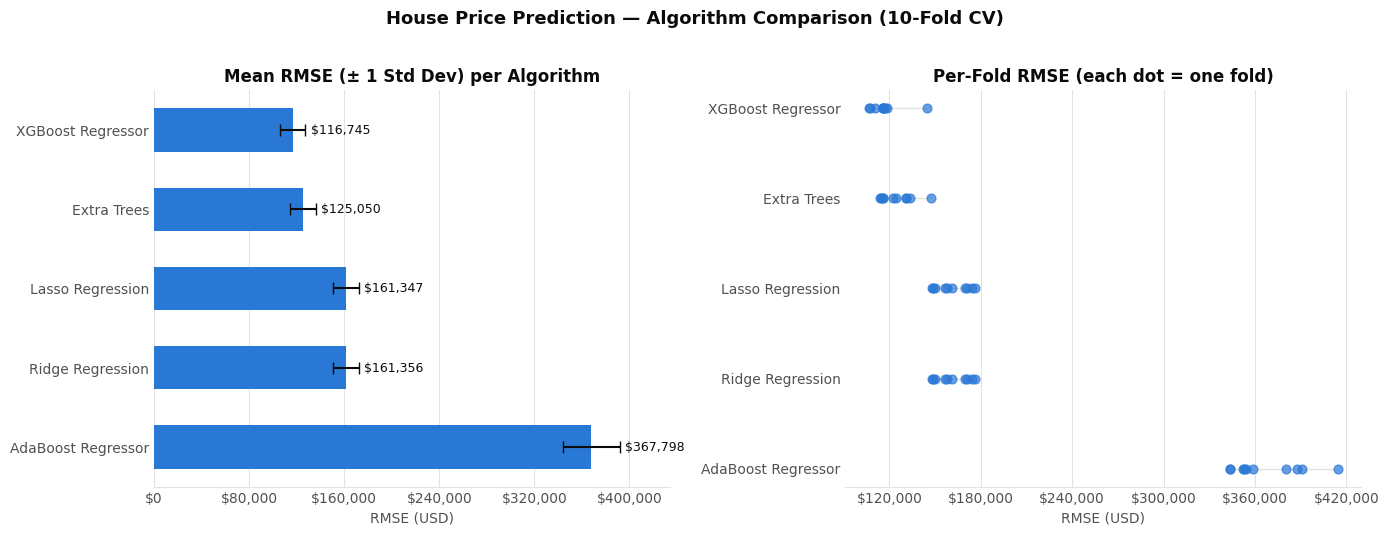

In [15]:
# Chart colours — matching the instructor's notebook palette
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE ($)"].values
stds = summary["Std RMSE ($)"].values

ax1.barh(positions, means, color=BAR_COLOR, height=0.55, zorder=2)
ax1.errorbar(means, positions, xerr=stds, fmt="none",
             color=TEXT_COLOR, capsize=4, linewidth=1.5, zorder=3)

# Value labels are placed just beyond the right end of each whisker
for pos, mean, std in zip(positions, means, stds):
    ax1.text(mean + std + means.max() * 0.012, pos, f"${mean:,.0f}",
             va="center", ha="left", color=TEXT_COLOR, fontsize=9)

ax1.set_xlim(0, means.max() * 1.18)
ax1.set_yticks(positions)
ax1.set_yticklabels(order, color=TEXT_COLOR, fontsize=10)
ax1.invert_yaxis()
ax1.set_xlabel("RMSE (USD)", color=MUTED_TEXT)
ax1.set_title("Mean RMSE (± 1 Std Dev) per Algorithm", color=TEXT_COLOR, fontweight="bold")
style_axis(ax1)

# ---- Chart 2: per-fold RMSE dots ----
for i, name in enumerate(order):
    fold_values = per_fold_table[name].values
    ax2.scatter(fold_values, [i] * K, color=BAR_COLOR, s=40, zorder=2, alpha=0.7)
    ax2.plot([fold_values.min(), fold_values.max()], [i, i],
             color=GRID_COLOR, linewidth=1, zorder=1)

ax2.set_yticks(positions)
ax2.set_yticklabels(order, color=TEXT_COLOR, fontsize=10)
ax2.invert_yaxis()
ax2.set_xlabel("RMSE (USD)", color=MUTED_TEXT)
ax2.set_title("Per-Fold RMSE (each dot = one fold)", color=TEXT_COLOR, fontweight="bold")
style_axis(ax2)

fig.suptitle("House Price Prediction — Algorithm Comparison (10-Fold CV)",
             color=TEXT_COLOR, fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from the 10-fold cross validation recorded in this notebook, on all 21,597 cleaned houses. A new run (for example in Google Colab) can differ slightly.

1. **XGBoost Regressor achieves the lowest mean RMSE ($116,745)**, followed by Extra Trees ($125,050). XGBoost has the lowest error on 9 of the 10 folds (Step 9.1). Both are tree ensembles, which can model non-linear effects and interactions, for example that the same size and grade sell for very different prices in different neighbourhoods.
2. **Ridge and Lasso are almost identical** (mean RMSE $161,356 and $161,347) and are about 38% worse than XGBoost. With `alpha=1.0` the penalty is tiny compared with prices in the hundreds of thousands of dollars, so both behave almost like ordinary linear regression: a straight-line relationship cannot fully capture the effect of location and quality on price.
3. **AdaBoost is the weakest algorithm ($367,798, 68.1% of the average price)**, even worse than the linear models. With its default settings it combines only 50 shallow trees (maximum depth 3), which is too simple for prices that range from $78,000 to $7,700,000.
4. **Fold-to-fold variation is large, but the ranking is stable.** The standard deviation of XGBoost is $10,541 (9% of its mean), and its RMSE ranges from $106,593 on the best fold to $144,502 on the worst fold. This is because house prices are strongly right-skewed (Step 3.1): a fold that contains a few very expensive houses gets a higher RMSE for every algorithm. The gap between XGBoost and Extra Trees ($8,305) is smaller than one standard deviation, but all algorithms are tested on the same folds and XGBoost wins 9 of 10, so its advantage is consistent.
5. **Practical error rate:** the best model is off by about $116,745 on average, which is 21.6% of the average price ($540,136). Because RMSE is dominated by the few luxury houses, the error on a typical house is expected to be smaller in dollars. The model is useful as a price estimate, but not as an exact valuation.
6. **Training time:** in the run recorded above (see the Time column in Step 9.2), Extra Trees was by far the slowest algorithm, while XGBoost trained quickly and gave the best accuracy.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now discarded.

We select the algorithm with the **lowest mean RMSE** from the summary table.

In [16]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")

Best algorithm : XGBoost Regressor
Expected RMSE  : $116,744.76 (+/- $10,541.23)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know which algorithm works best, we train it on **all 21,597 houses**. There is no separate test set here, because the cross-validation RMSE from Step 9 is already our unbiased estimate of how well this model will perform on new, unseen houses.

In [17]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} houses.")

Final XGBoost Regressor model trained on 21,597 houses.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it can predict directly from raw house details without any manual preprocessing.

To download `model.pkl` to your computer in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel on the left.

> **Important for deployment:** `model.pkl` must be committed to your GitHub repository so the Streamlit app can load it. See `README.md` for instructions.

In [18]:
MODEL_FILE = "model.pkl"
DOWNLOAD_MODEL = False

import joblib

# Save with joblib compression (compress=3) to keep the file small, so that GitHub (100 MB limit) accepts it
joblib.dump(final_model, MODEL_FILE, compress=3)

size_bytes = os.path.getsize(MODEL_FILE)
size_mb = size_bytes / (1024 * 1024)

print(f"Trained model saved as '{MODEL_FILE}'")
print(f"File size: {size_mb:.2f} MB")

if size_mb > 90:
    print("WARNING: model exceeds 90 MB limit.")
else:
    print("✓ File size is within the 90 MB limit.")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Trained model saved as 'model.pkl'
File size: 0.74 MB
✓ File size is within the 90 MB limit.


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example house below, so that **Run all** works without stopping. To type in your own house, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [19]:
USE_INTERACTIVE_INPUT = False

# Default example: a 3-bedroom, 2.5-bathroom, 2-floor house built in 1995 in ZIP code 98052
example_house = {
    "bedrooms": 3,
    "bathrooms": 2.5,
    "sqft_living": 2000,
    "sqft_lot": 5000,
    "floors": 2.0,
    "waterfront": 0,
    "view": 0,
    "condition": 3,
    "grade": 8,
    "sqft_above": 2000,
    "sqft_basement": 0,
    "yr_built": 1995,
    "yr_renovated": 0,
    "lat": 47.68,
    "long": -122.12,
    "sqft_living15": 2000,
    "sqft_lot15": 5000,
    "zipcode": "98052",
}

def get_house_input():
    print("Enter House Details (valid ranges from dataset shown):")
    for column in numeric_features:
        print(f"  {column:14s}: {X[column].min():,.4g} - {X[column].max():,.4g}")
    print(f"  {'zipcode':14s}: any ZIP code in the dataset (e.g. 98052)")
    user_values = {column: float(input(f"  Enter {column:14s}: ")) for column in numeric_features}
    user_values["zipcode"] = input(f"  Enter {'zipcode':14s}: ").strip()
    return user_values

if USE_INTERACTIVE_INPUT:
    user_input = get_house_input()
else:
    user_input = example_house
    print("Using example house:")
    for k, v in user_input.items():
        print(f"  {k:14s}: {v}")

Using example house:
  bedrooms      : 3
  bathrooms     : 2.5
  sqft_living   : 2000
  sqft_lot      : 5000
  floors        : 2.0
  waterfront    : 0
  view          : 0
  condition     : 3
  grade         : 8
  sqft_above    : 2000
  sqft_basement : 0
  yr_built      : 1995
  yr_renovated  : 0
  lat           : 47.68
  long          : -122.12
  sqft_living15 : 2000
  sqft_lot15    : 5000
  zipcode       : 98052


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. There is no need to encode or scale it manually: the saved pipeline handles everything automatically.

In [20]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode
0,3,2.5,2000,5000,2.0,0,0,3,8,2000,0,1995,0,47.68,-122.12,2000,5000,98052


## Step 11.3: Load the Saved Model

In [21]:
import joblib

try:
    loaded_model = joblib.load(MODEL_FILE)
except Exception:
    with open(MODEL_FILE, "rb") as f:
        loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'model.pkl': XGBRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen house and return the prediction to the user.

In [22]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: ${predicted_price:,.2f} USD")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about ${best_mean_rmse:,.0f}")

Predicted Price: $562,215.81 USD
Typical error (cross-validation RMSE of XGBoost Regressor): about $116,745


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (real-estate agents, property valuers) is used to improve the model. Potential improvements for this system:

1. **Feature Engineering**: add features such as the age of the house at the time of sale (sale year − `yr_built`), a "was renovated" flag, the total number of rooms, or the distance from downtown Seattle calculated from `lat` and `long`.
2. **Hyperparameter Tuning**: optimize tree depth, learning rate, number of trees and regularisation using `RandomizedSearchCV` or Bayesian optimisation across folds.
3. **Target Transformation**: evaluate a `log(price)` transformation so that errors on cheap and expensive houses are treated in proportion to their price.
4. **Use the Sale Date**: the `date` column was dropped in this notebook; adding the month or the sale year would let the model follow market trends and seasonality.
5. **Deployment Monitoring**: log the details users type into the app, and compare predictions with real sale prices over time to detect drift in the housing market.
6. **App Enhancements**: add batch upload (CSV) so an agency can price many listings at once, and show a price range instead of a single number.

# Conclusion

In this notebook we compared **5 regression algorithms** on the **full King County house sales dataset (21,597 houses after cleaning)** using **10-fold cross validation** and **RMSE**.

- **XGBoost Regressor** achieved the lowest mean RMSE ($116,745), followed by **Extra Trees** ($125,050). XGBoost was selected, retrained on all houses, saved as `model.pkl`, and verified inside the application phase.
- **The two tree ensembles are clearly better than the linear models:** XGBoost has about 28% lower error and Extra Trees about 22% lower error than Ridge and Lasso (about $161,351), which suggests that house prices depend non-linearly on size, quality and location.
- **AdaBoost with default settings performed worst** ($367,798), so it would need tuning before it could be used for this problem.
- The 10-fold cross validation setup guarantees that every house is used for testing exactly once, giving a fair and dependable comparison.
- The final model is deployed as a web application: https://house-price-prediction-shaiza-butt.streamlit.app/

### Algorithm Ranking Summary

| Rank | Algorithm | Mean RMSE ($) | Std RMSE ($) |
|:---:|---|:---:|:---:|
| 1 | XGBoost Regressor | $116,745 | $10,541 |
| 2 | Extra Trees | $125,050 | $10,933 |
| 3 | Lasso Regression | $161,347 | $10,869 |
| 4 | Ridge Regression | $161,356 | $10,851 |
| 5 | AdaBoost Regressor | $367,798 | $23,925 |